# Major Project: Dual Quantum-Resistant IoT
## Integrating Federated Learning with Forward-Secure Lattice IBE, CRYSTALS-Dilithium-3 & 6-Model Behavioral Trust Scoring

**Base:** Forward-Secure Lattice-Based IBE with Trust-Based Verification (Minor Project)

**Extension:** (1) Replace static +1/-1 trust scoring with ML-driven behavioral anomaly detection using a **6-model ensemble** (Isolation Forest, Random Forest, SVM, KNN, Decision Tree, and MLP Neural Network), and (2) integrate privacy-preserving **Federated Learning (FedAvg)** where gateway updates are quantized, encrypted per-epoch with Dual Regev Lattice fs-IBE, and authenticated with real **NIST FIPS 204 CRYSTALS-Dilithium-3 (ML-DSA-65)** digital signatures.

---

### What This Notebook Demonstrates

| Section | Description |
|---------|-------------|
| **1. Setup** | Load the base fs-IBE system and ML modules |
| **2. Attack Simulation** | Generate 40,000 normal, attack, and ambiguous/noisy IoT traffic windows |
| **3. ML Model Training** | Train 6-model ensemble engine |
| **4. Visual Analysis** | 2x4 confusion matrix grid, feature importance, trust trajectories |
| **5. Comparison** | Static vs six-model ML trust (metrics table + charts) |
| **6. Live Demo** | Real-time ML trust scoring on simulated queries |
| **7. Federated Learning** | Dilithium-signed, lattice-encrypted FedAvg updates |
| **8. Summary** | Ensemble, comparison, FL results, novelty, and project files |

---
## 1. Setup & Imports

In [1]:
import sys, os, time, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

# Register lattice modules for import
import lattice_infrastructure
sys.modules["LatticeCrypto"] = lattice_infrastructure

import lattice_infrastructure as P1
from forward_security import UserOps
from Trust_Model import (TrustManager, DilithiumStub, Query, QueryValidator,
                         FeatureExtractor, match_query_to_data)
from ml_trust_engine import MLTrustEngine, FEATURE_NAMES, SUPERVISED_MODEL_NAMES
from attack_simulator import (generate_full_dataset, save_dataset, load_dataset,
                              FEATURE_NAMES as ATK_FEATURES)

# Visualization
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
matplotlib.rcParams.update({'font.size': 11, 'figure.dpi': 120})

print("All modules loaded successfully.")
print(f"Lattice Infrastructure: n={P1.LatticeParams().n}, q={P1.LatticeParams().q}")

All modules loaded successfully.
Lattice Infrastructure: n=16, q=3329


---
## 2. Attack Traffic Simulation

We generate **synthetic IoT traffic** with 5 attack types to train our ML models:

| Attack Type | Description | Key Behavioral Signal |
|---|---|---|
| **Replay** | Reuses old valid queries | High epoch mismatch rate |
| **Flood** | Overwhelms with query volume | Very high frequency, tiny intervals |
| **Epoch Manipulation** | Requests wrong/expired epochs | Very high epoch mismatch |
| **Sybil** | Multiple fake identities | High frequency + sig failures |
| **Probing** | Slow methodical exploration | Unusual payload sizes |

In [2]:
# Generate deployment-shaped temporal windows with correlated features.
# The default mix is intentionally imbalanced: mostly normal traffic with
# rare attacks and ambiguous boundary cases.
dataset = generate_full_dataset(n_ambiguous=5000)

# Save and load as DataFrame
save_dataset(dataset, "training_data.csv")
X, y, attack_types = load_dataset("training_data.csv")

df = pd.read_csv("training_data.csv")
print(f"Total samples: {len(df)}")
print(f"Normal: {(df['label']==0).sum()}, Malicious: {(df['label']==1).sum()}")
print(f"\nAttack type distribution:")
print(df['attack_type'].value_counts().to_string())

  Saved 40000 samples to training_data.csv


Total samples: 40000
Normal: 32526, Malicious: 7474

Attack type distribution:
attack_type
normal                30000
ambiguous              5000
sybil                  1000
epoch_manipulation     1000
flood                  1000
replay                 1000
probing                1000


### 2.1 Dataset Distribution Visualization

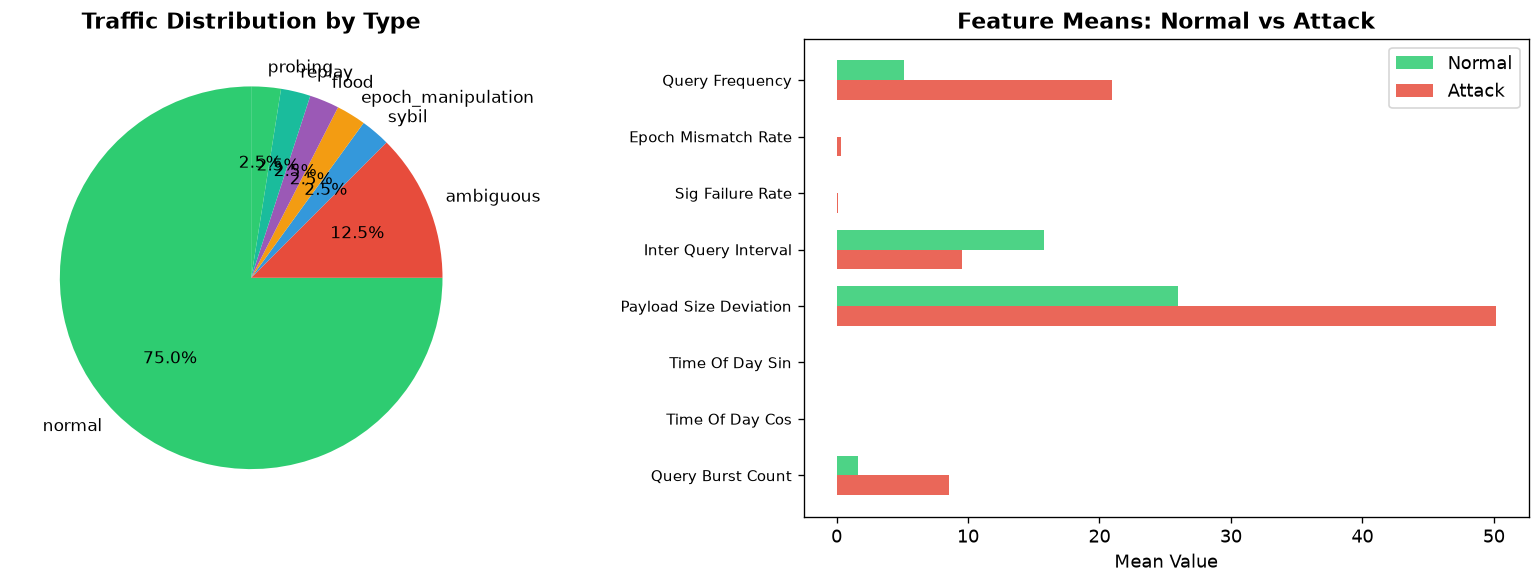

Saved: dataset_distribution.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart - attack type distribution
type_counts = df['attack_type'].value_counts()
colors = ['#2ecc71', '#e74c3c', '#3498db', '#f39c12', '#9b59b6', '#1abc9c']
axes[0].pie(type_counts.values, labels=type_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, textprops={'fontsize': 10})
axes[0].set_title('Traffic Distribution by Type', fontsize=13, fontweight='bold')

# Bar chart - feature means by label
normal_means = df[df['label']==0][FEATURE_NAMES].mean()
attack_means = df[df['label']==1][FEATURE_NAMES].mean()
x_pos = np.arange(len(FEATURE_NAMES))
w = 0.35
axes[1].barh(x_pos - w/2, normal_means, w, label='Normal', color='#2ecc71', alpha=0.85)
axes[1].barh(x_pos + w/2, attack_means, w, label='Attack', color='#e74c3c', alpha=0.85)
axes[1].set_yticks(x_pos)
axes[1].set_yticklabels([f.replace('_', ' ').title() for f in FEATURE_NAMES], fontsize=9)
axes[1].set_xlabel('Mean Value')
axes[1].set_title('Feature Means: Normal vs Attack', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('dataset_distribution.png', bbox_inches='tight')
display(Image(filename='dataset_distribution.png'))
plt.close()
print("Saved: dataset_distribution.png")

---
## 3. ML Trust Engine Training

### 6-Model Ensemble Architecture

```
Query Features (8 dims)
        |
        v
  [StandardScaler]
        |
   +----+----+----+----+----+----+
   |    |    |    |    |    |    |
   v    v    v    v    v    v    v
 [IF] [RF] [SVM] [KNN] [DT] [MLP]
   |    |    |    |    |    |    |
   v    v    v    v    v    v    v
 Anom  Prob  Prob  Prob Prob Prob
 Score
   |    |    |    |    |    |    |
   +----+----+----+----+----+----+
                  |
                  v
       Weighted Majority Voting
       (is_anomaly, confidence)
```

| Model | Type | Description |
|---|---|---|
| **Isolation Forest** | Unsupervised | Detects novel/unknown attacks without labels |
| **Random Forest** | Supervised | Ensemble tree classifier, high accuracy |
| **SVM** | Supervised | Kernel-based margin classifier |
| **KNN** | Supervised | Instance-based distance classifier |
| **Decision Tree** | Supervised | Interpretable tree-based classifier |
| **MLP** | Supervised | Neural network deep learning classifier |

In [4]:
# Train the ML Trust Engine (all 6 models)
engine = MLTrustEngine(n_estimators_iso=100, n_estimators_rf=100)
metrics = engine.train(X, y, verbose=True)
engine.save_models("models")

  ML Trust Engine — Training


  Training samples: 32000


  Test samples: 8000


  Features: 8



  Training Isolation Forest (unsupervised)...



  Training Random Forest...


... (21 outputs left out)

    payload_size_deviation        : 0.0636


    time_of_day_sin               : 0.0079


    time_of_day_cos               : 0.0070


  Models saved to models/


---
## 4. Visual Analysis

### 4.1 Confusion Matrix Heatmaps (All 6 Models + Combined)

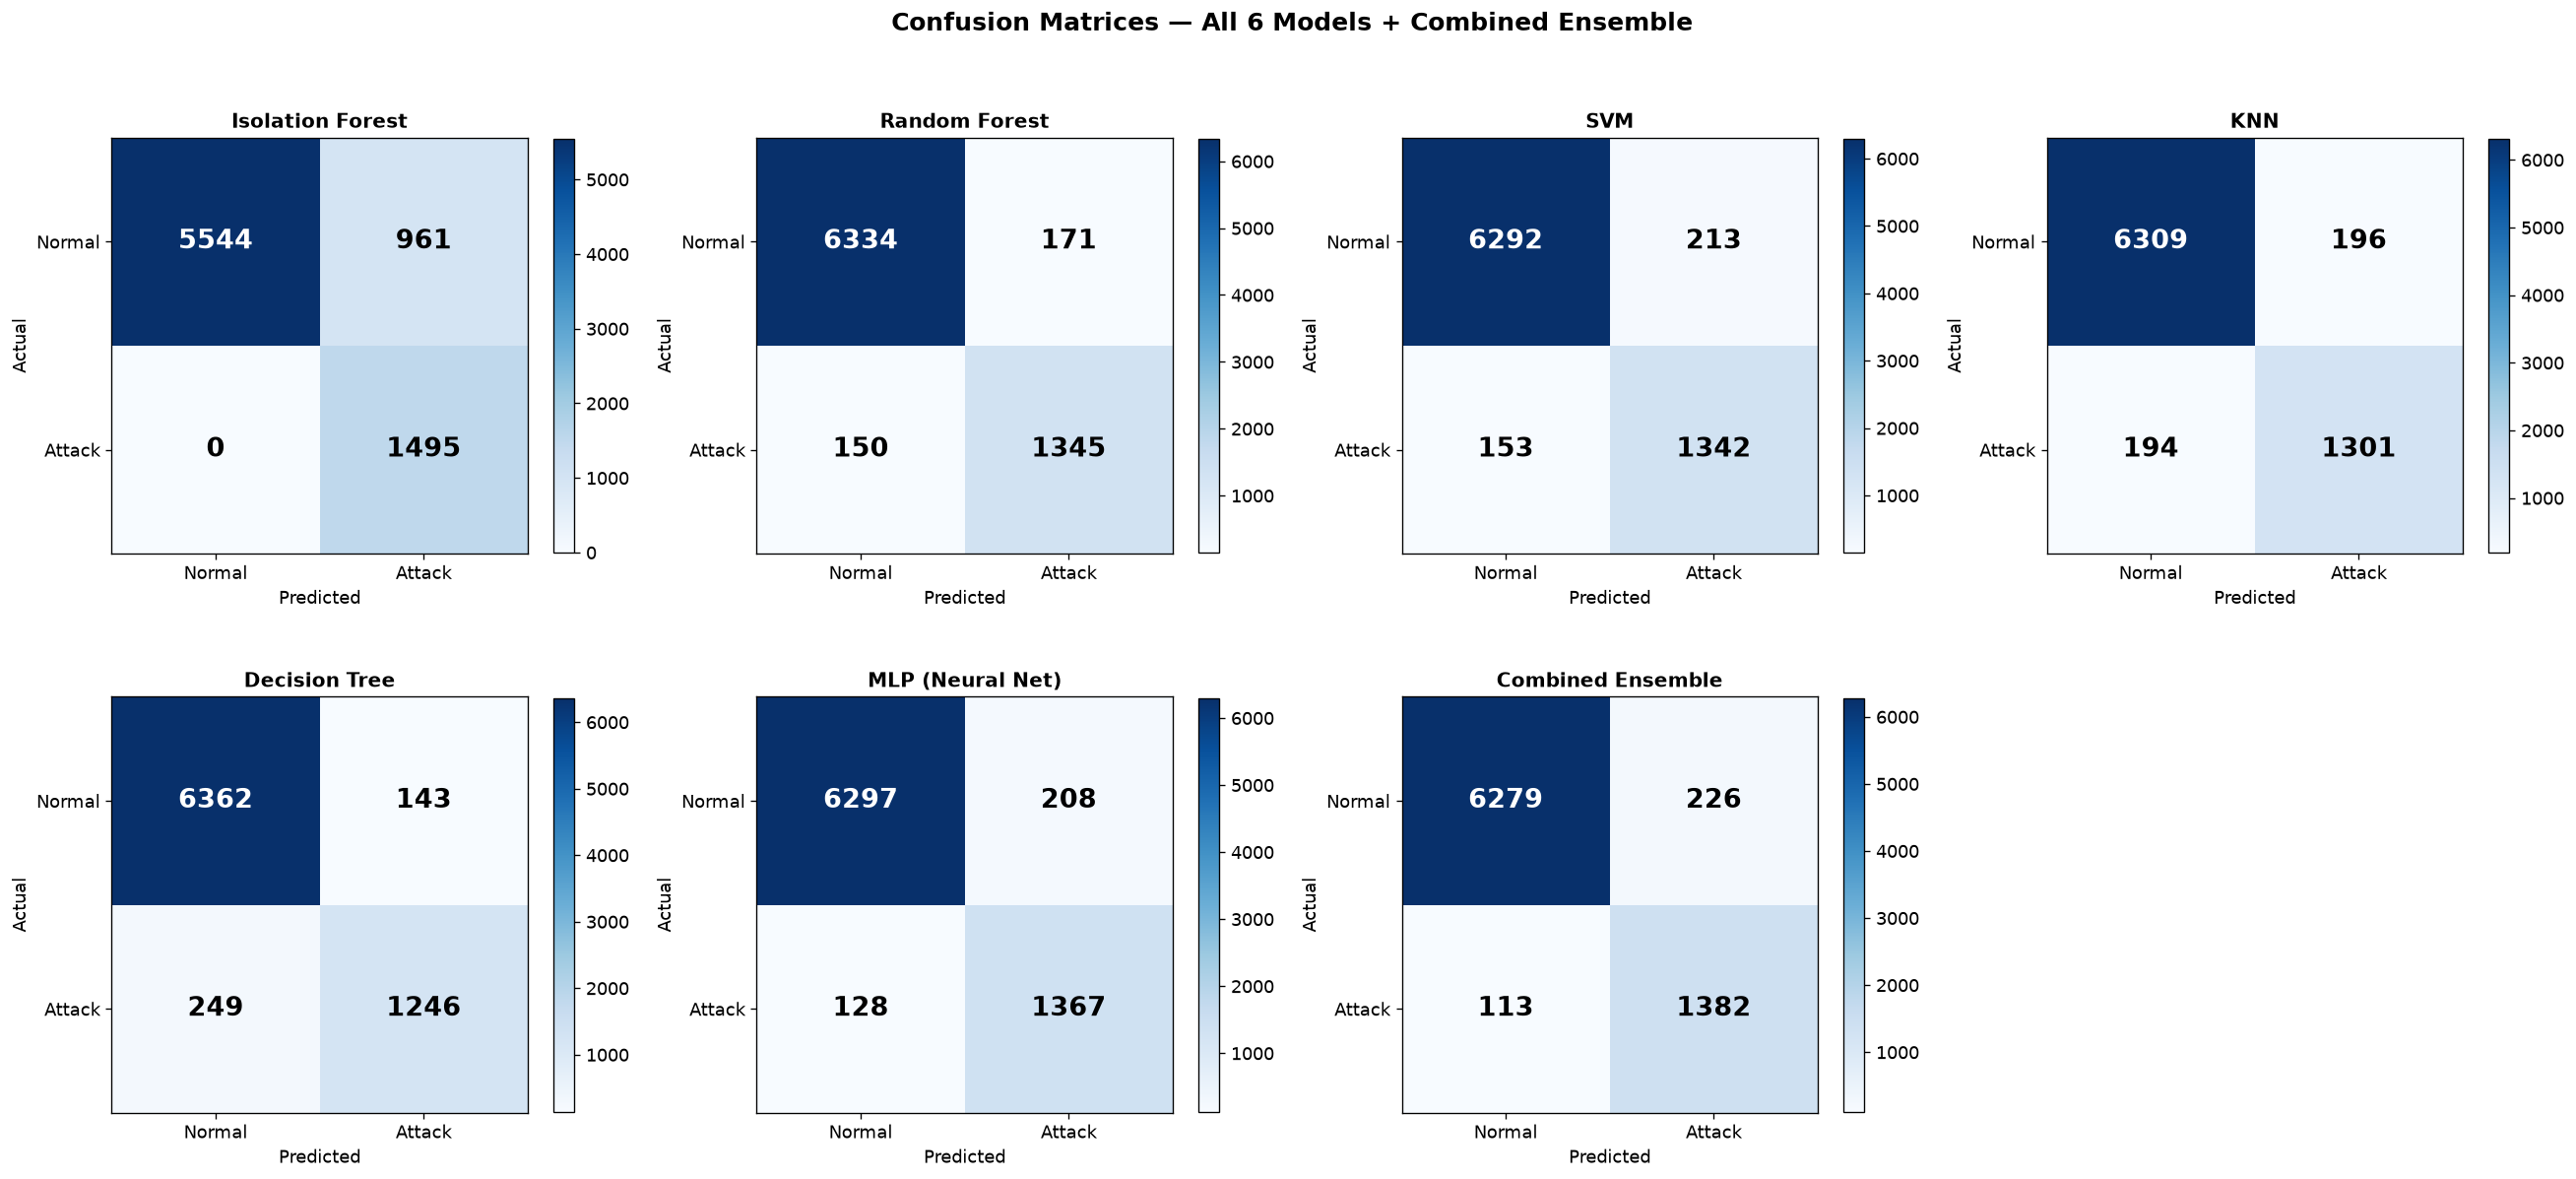

Saved: confusion_matrices.png


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_test_scaled = engine.scaler.transform(X_test)

# Get predictions from all models
iso_pred = (engine.isolation_forest.predict(X_test_scaled) == -1).astype(int)
rf_pred = engine.random_forest.predict(X_test_scaled)
svm_pred = engine.svm.predict(X_test_scaled)
knn_pred = engine.knn.predict(X_test_scaled)
dt_pred = engine.decision_tree.predict(X_test_scaled)
mlp_pred = engine.mlp.predict(X_test_scaled)

# Get probabilities for combined prediction
iso_scores = -engine.isolation_forest.score_samples(X_test_scaled)
supervised_probas = {
    'random_forest': engine.random_forest.predict_proba(X_test_scaled)[:, 1],
    'svm': engine.svm.predict_proba(X_test_scaled)[:, 1],
    'knn': engine.knn.predict_proba(X_test_scaled)[:, 1],
    'decision_tree': engine.decision_tree.predict_proba(X_test_scaled)[:, 1],
    'mlp': engine.mlp.predict_proba(X_test_scaled)[:, 1],
}
supervised_preds = {
    'random_forest': rf_pred, 'svm': svm_pred, 'knn': knn_pred,
    'decision_tree': dt_pred, 'mlp': mlp_pred,
}
combined = engine._combine_predictions_multi(iso_pred, iso_scores, supervised_preds, supervised_probas)

# Plot confusion matrices: 2 rows x 4 columns
all_preds = [
    (iso_pred, 'Isolation Forest'), (rf_pred, 'Random Forest'),
    (svm_pred, 'SVM'), (knn_pred, 'KNN'),
    (dt_pred, 'Decision Tree'), (mlp_pred, 'MLP (Neural Net)'),
    (combined, 'Combined Ensemble'),
]
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes_flat = axes.flatten()

for idx, (pred, title) in enumerate(all_preds):
    ax = axes_flat[idx]
    cm_i = confusion_matrix(y_test, pred)
    im = ax.imshow(cm_i, cmap='Blues', interpolation='nearest')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(['Normal','Attack'])
    ax.set_yticklabels(['Normal','Attack'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm_i[i,j]), ha='center', va='center',
                    fontsize=16, fontweight='bold',
                    color='white' if cm_i[i,j] > cm_i.max()/2 else 'black')
    plt.colorbar(im, ax=ax, shrink=0.8)

# Hide the unused 8th subplot
axes_flat[7].set_visible(False)

plt.suptitle('Confusion Matrices — All 6 Models + Combined Ensemble', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('confusion_matrices.png', bbox_inches='tight')
display(Image(filename='confusion_matrices.png'))
plt.close()
print("Saved: confusion_matrices.png")

### 4.2 Feature Importance (Random Forest)

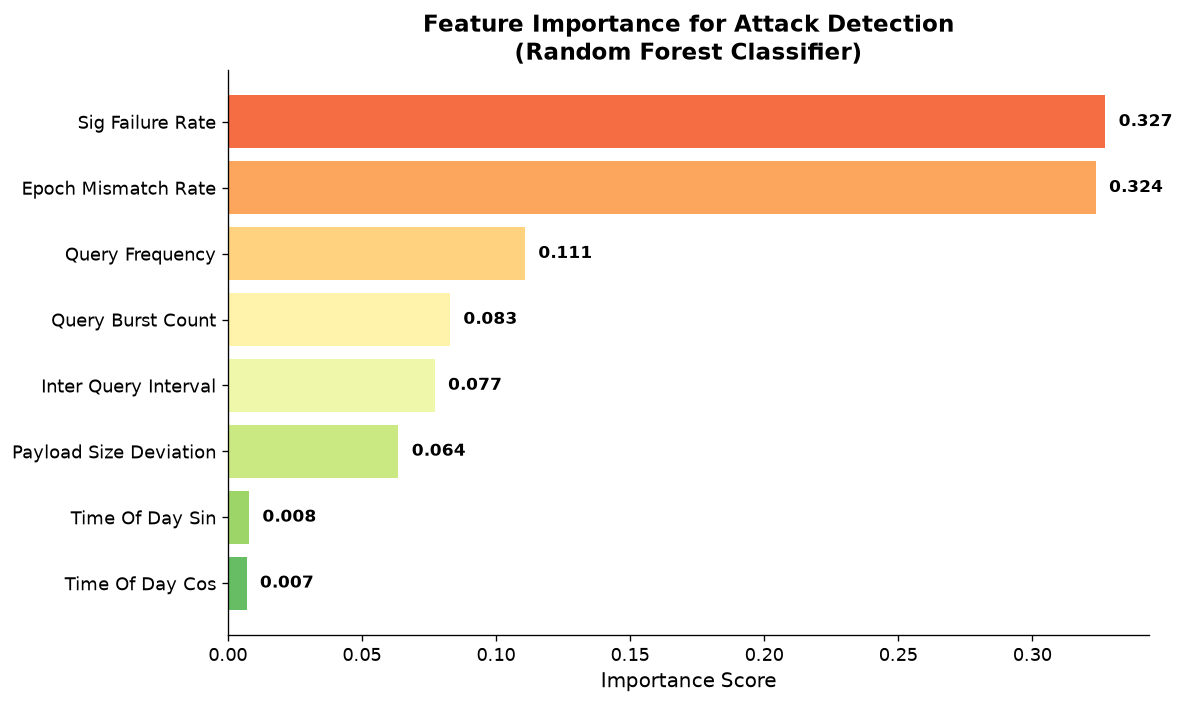

Saved: feature_importance.png


In [6]:
importances = engine.random_forest.feature_importances_
sorted_idx = np.argsort(importances)
labels = [FEATURE_NAMES[i].replace('_', ' ').title() for i in sorted_idx]

fig, ax = plt.subplots(figsize=(10, 6))
colors_grad = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(sorted_idx)))
bars = ax.barh(range(len(sorted_idx)), importances[sorted_idx], color=colors_grad)
ax.set_yticks(range(len(sorted_idx)))
ax.set_yticklabels(labels, fontsize=11)
ax.set_xlabel('Importance Score', fontsize=12)
ax.set_title('Feature Importance for Attack Detection\n(Random Forest Classifier)',
             fontsize=14, fontweight='bold')

for i, (val, bar) in enumerate(zip(importances[sorted_idx], bars)):
    ax.text(val + 0.005, i, f'{val:.3f}', va='center', fontsize=10, fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('feature_importance.png', bbox_inches='tight')
display(Image(filename='feature_importance.png'))
plt.close()
print("Saved: feature_importance.png")

### 4.3 Trust Score Trajectory Over Time

This plot shows how trust scores evolve for different device behaviors:
- **Legitimate device**: Trust score climbs and stays high
- **Flood attacker**: Trust rapidly drops below zero (blocked)
- **Replay attacker**: Trust degrades as epoch mismatches accumulate

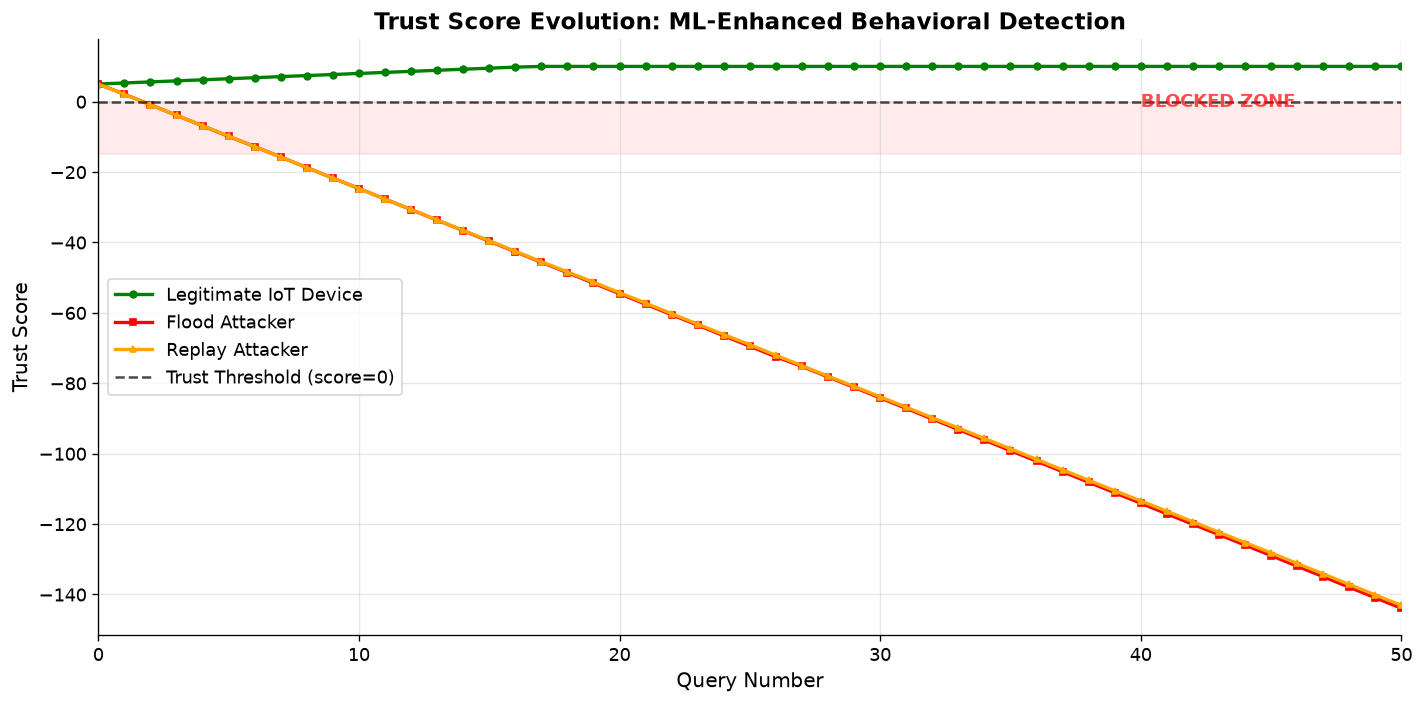

Saved: trust_trajectory.png


In [7]:
# Simulate trust score trajectories
np.random.seed(42)
n_steps = 50

def simulate_trajectory(engine, behavior='normal'):
    tm = TrustManager(ml_engine=engine)
    scores = [tm.get_score('dev')]
    for step in range(n_steps):
        if behavior == 'normal':
            features = {
                'query_frequency': np.random.uniform(2, 6),
                'epoch_mismatch_rate': np.random.uniform(0, 0.03),
                'sig_failure_rate': 0.0,
                'inter_query_interval': np.random.uniform(5, 20),
                'payload_size_deviation': np.random.uniform(0, 30),
                'time_of_day_sin': 0.5, 'time_of_day_cos': 0.866,
                'query_burst_count': np.random.choice([1, 2]),
            }
        elif behavior == 'flood':
            features = {
                'query_frequency': np.random.uniform(40, 90),
                'epoch_mismatch_rate': np.random.uniform(0, 0.15),
                'sig_failure_rate': np.random.uniform(0.1, 0.3),
                'inter_query_interval': np.random.uniform(0.01, 0.3),
                'payload_size_deviation': np.random.uniform(0, 20),
                'time_of_day_sin': 0.5, 'time_of_day_cos': 0.866,
                'query_burst_count': np.random.randint(15, 45),
            }
        elif behavior == 'replay':
            features = {
                'query_frequency': np.random.uniform(8, 18),
                'epoch_mismatch_rate': np.random.uniform(0.4, 0.7),
                'sig_failure_rate': np.random.uniform(0, 0.05),
                'inter_query_interval': np.random.uniform(1, 4),
                'payload_size_deviation': np.random.uniform(0, 15),
                'time_of_day_sin': 0.5, 'time_of_day_cos': 0.866,
                'query_burst_count': np.random.randint(3, 8),
            }
        tm.ml_score('dev', features)
        scores.append(tm.get_score('dev'))
    return scores

traj_normal = simulate_trajectory(engine, 'normal')
traj_flood = simulate_trajectory(engine, 'flood')
traj_replay = simulate_trajectory(engine, 'replay')

fig, ax = plt.subplots(figsize=(12, 6))
steps = range(n_steps + 1)
ax.plot(steps, traj_normal, 'g-o', markersize=4, label='Legitimate IoT Device', linewidth=2)
ax.plot(steps, traj_flood, 'r-s', markersize=4, label='Flood Attacker', linewidth=2)
ax.plot(steps, traj_replay, color='orange', marker='^', markersize=4, label='Replay Attacker', linewidth=2)
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label='Trust Threshold (score=0)')
ax.fill_between(steps, -15, 0, alpha=0.08, color='red')
ax.text(n_steps*0.8, -1.5, 'BLOCKED ZONE', fontsize=11, color='red', fontweight='bold', alpha=0.7)
ax.set_xlabel('Query Number', fontsize=12)
ax.set_ylabel('Trust Score', fontsize=12)
ax.set_title('Trust Score Evolution: ML-Enhanced Behavioral Detection',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='center left')
ax.set_xlim(0, n_steps)
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('trust_trajectory.png', bbox_inches='tight')
display(Image(filename='trust_trajectory.png'))
plt.close()
print("Saved: trust_trajectory.png")

---
## 5. Static vs ML-Enhanced Trust: Full Comparison

### Running the comparison benchmark

In [8]:
from ml_simulation import run_ml_trust_comparison

results = run_ml_trust_comparison(n=64, num_queries=100, num_attacks=100)

# Print results table
s, m = results['static'], results['ml']
print("=" * 65)
print("  STATIC vs ML-ENHANCED TRUST SCORING")
print("=" * 65)
print(f"  {'Metric':<25} {'Static':>15} {'ML-Enhanced':>15}")
print("  " + "-" * 55)
for k in ['accuracy','precision','recall','f1','fpr']:
    print(f"  {k:<25} {s[k]:>15.4f} {m[k]:>15.4f}")
print("  " + "-" * 55)
print(f"  {'TP (attacks caught)':<25} {s['tp']:>15} {m['tp']:>15}")
print(f"  {'FP (false alarms)':<25} {s['fp']:>15} {m['fp']:>15}")
print(f"  {'TN (legit accepted)':<25} {s['tn']:>15} {m['tn']:>15}")
print(f"  {'FN (attacks missed)':<25} {s['fn']:>15} {m['fn']:>15}")
print("  " + "-" * 55)
avg_inference = results['ml_avg_inference_ms']
if avg_inference is None:
    print("  ML Avg Inference: not measured")
else:
    print(f"  ML Avg Inference: {avg_inference:.2f} ms")
print("=" * 65)

  STATIC vs ML-ENHANCED TRUST SCORING
  Metric                             Static     ML-Enhanced
  -------------------------------------------------------
  accuracy                           0.6000          0.9000
  precision                          1.0000          1.0000
  recall                             0.2000          0.8000
  f1                                 0.3333          0.8889
  fpr                                0.0000          0.0000
  -------------------------------------------------------
  TP (attacks caught)                    20              80
  FP (false alarms)                       0               0
  TN (legit accepted)                   100             100
  FN (attacks missed)                    80              20
  -------------------------------------------------------
  ML Avg Inference: 119.56 ms


### 5.1 Comparison Bar Chart

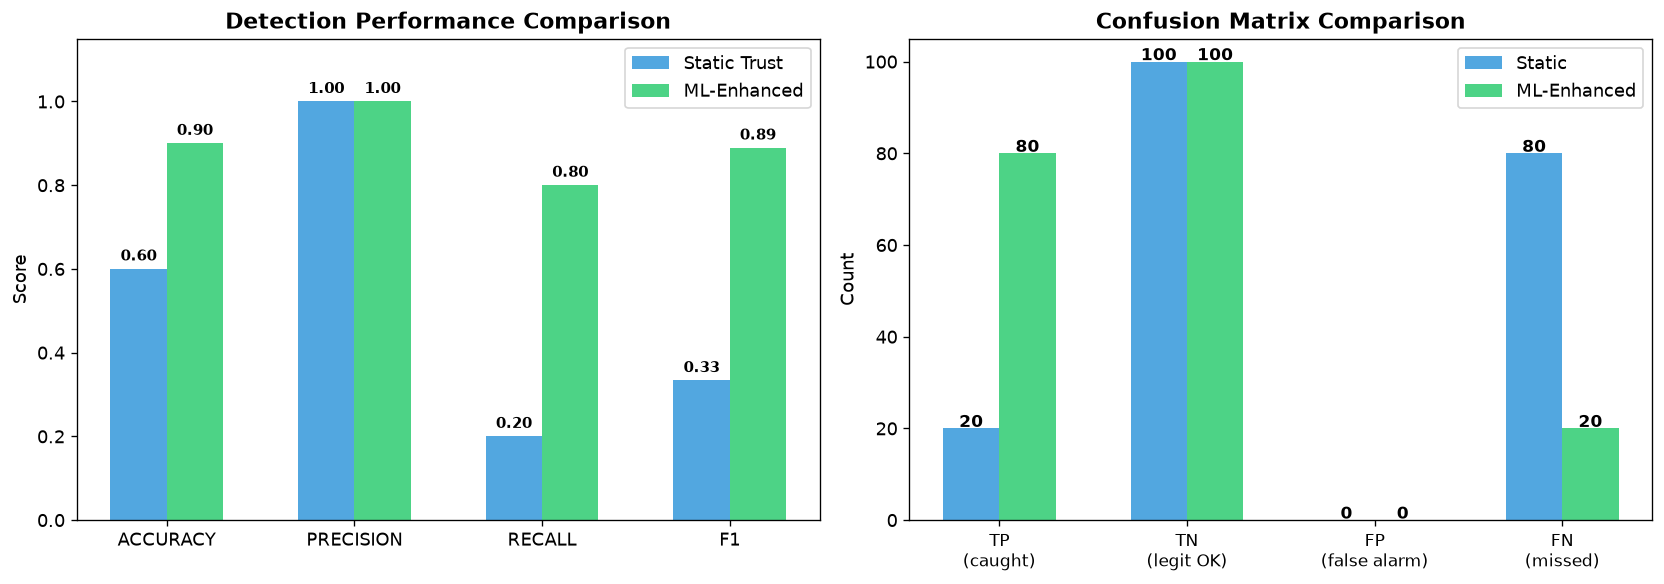

Saved: comparison_chart.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Metrics comparison
metrics_keys = ['accuracy', 'precision', 'recall', 'f1']
static_vals = [results['static'][k] for k in metrics_keys]
ml_vals = [results['ml'][k] for k in metrics_keys]

x = np.arange(len(metrics_keys))
w = 0.3
axes[0].bar(x - w/2, static_vals, w, label='Static Trust', color='#3498db', alpha=0.85)
axes[0].bar(x + w/2, ml_vals, w, label='ML-Enhanced', color='#2ecc71', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels([k.upper() for k in metrics_keys], fontsize=11)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel('Score')
axes[0].set_title('Detection Performance Comparison', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
for i, (sv, mv) in enumerate(zip(static_vals, ml_vals)):
    axes[0].text(i - w/2, sv + 0.02, f'{sv:.2f}', ha='center', fontsize=9, fontweight='bold')
    axes[0].text(i + w/2, mv + 0.02, f'{mv:.2f}', ha='center', fontsize=9, fontweight='bold')

# Confusion matrix counts
labels = ['TP\n(caught)', 'TN\n(legit OK)', 'FP\n(false alarm)', 'FN\n(missed)']
static_cm = [s['tp'], s['tn'], s['fp'], s['fn']]
ml_cm = [m['tp'], m['tn'], m['fp'], m['fn']]
x2 = np.arange(4)
axes[1].bar(x2 - w/2, static_cm, w, label='Static', color='#3498db', alpha=0.85)
axes[1].bar(x2 + w/2, ml_cm, w, label='ML-Enhanced', color='#2ecc71', alpha=0.85)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(labels, fontsize=10)
axes[1].set_ylabel('Count')
axes[1].set_title('Confusion Matrix Comparison', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)
for i, (sv, mv) in enumerate(zip(static_cm, ml_cm)):
    axes[1].text(i - w/2, sv + 0.3, str(sv), ha='center', fontsize=10, fontweight='bold')
    axes[1].text(i + w/2, mv + 0.3, str(mv), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('comparison_chart.png', bbox_inches='tight')
display(Image(filename='comparison_chart.png'))
plt.close()
print("Saved: comparison_chart.png")

### 5.2 ML Model Training Performance (All 6 Models)

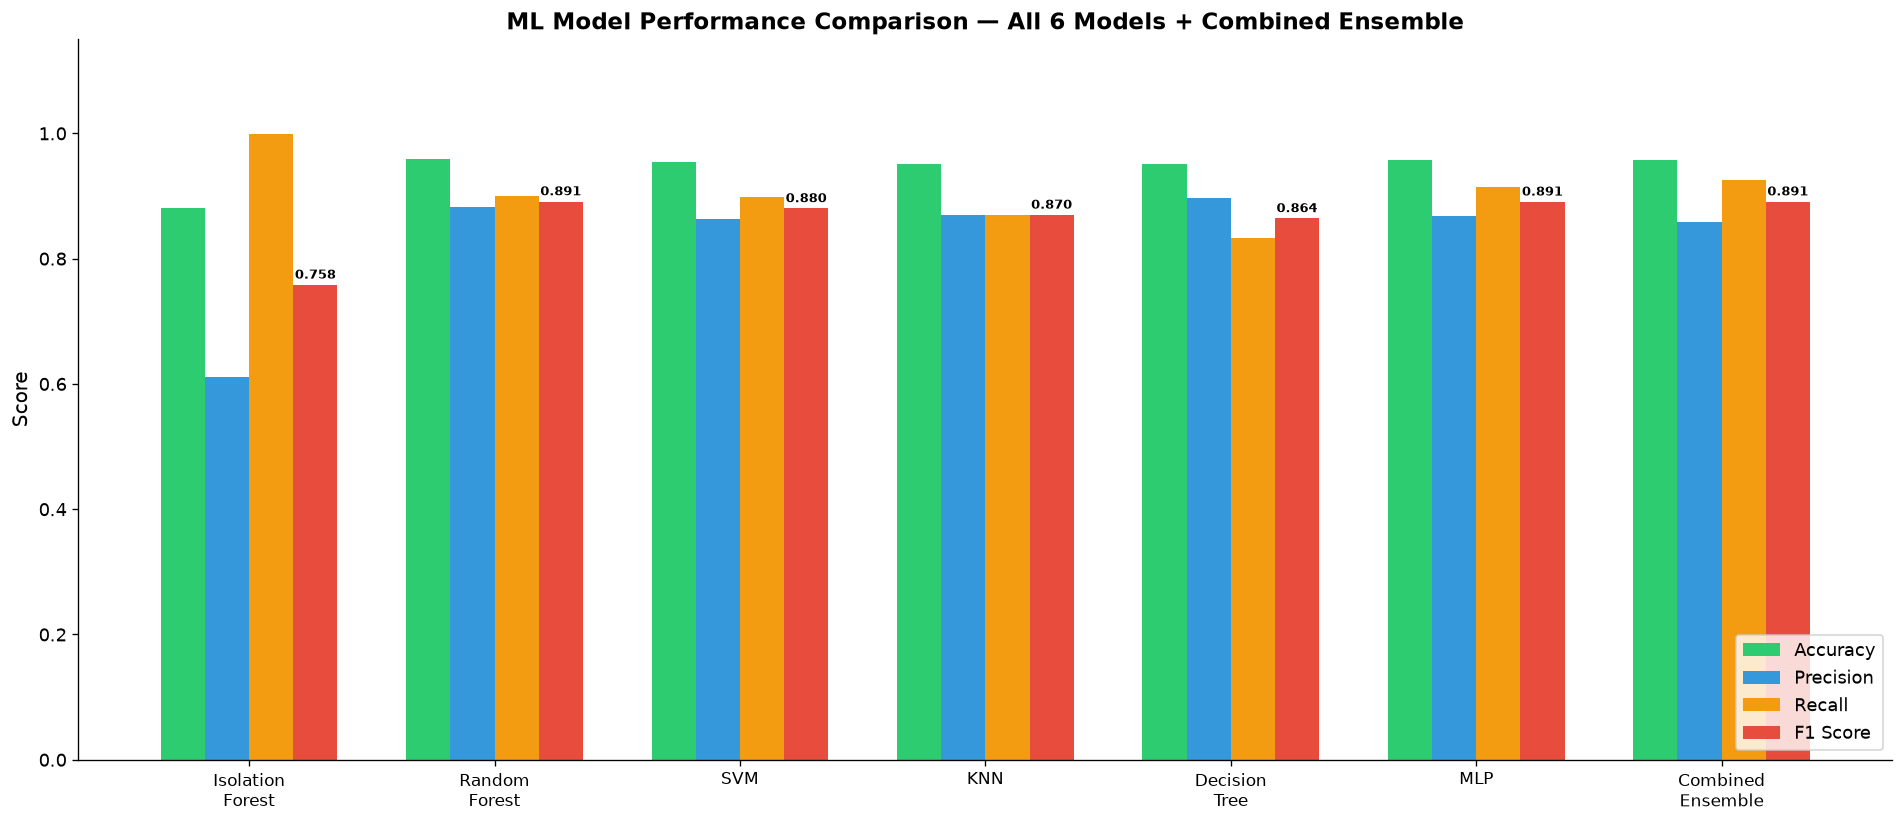

Saved: model_performance.png

  Model                    Accuracy  Precision     Recall         F1
  -----------------------------------------------------------------
  Isolation Forest           0.8808     0.6105     0.9993     0.7580
  Random Forest              0.9589     0.8825     0.8997     0.8910
  SVM                        0.9543     0.8630     0.8977     0.8800
  KNN                        0.9513     0.8691     0.8702     0.8697
  Decision Tree              0.9510     0.8970     0.8334     0.8641
  MLP                        0.9580     0.8679     0.9144     0.8906
  Combined Ensemble          0.9576     0.8590     0.9251     0.8908


In [10]:
tm = results['ml_train_metrics']

# All model keys and display names
model_keys = ['iso', 'random_forest', 'svm', 'knn', 'decision_tree', 'mlp', 'combined']
model_names = ['Isolation\nForest', 'Random\nForest', 'SVM', 'KNN', 'Decision\nTree', 'MLP', 'Combined\nEnsemble']
acc = [tm[f'{k}_accuracy'] for k in model_keys]
prec = [tm[f'{k}_precision'] for k in model_keys]
rec = [tm[f'{k}_recall'] for k in model_keys]
f1s = [tm[f'{k}_f1'] for k in model_keys]

fig, ax = plt.subplots(figsize=(16, 7))
x = np.arange(len(model_names))
w = 0.18
ax.bar(x - 1.5*w, acc, w, label='Accuracy', color='#2ecc71')
ax.bar(x - 0.5*w, prec, w, label='Precision', color='#3498db')
ax.bar(x + 0.5*w, rec, w, label='Recall', color='#f39c12')
ax.bar(x + 1.5*w, f1s, w, label='F1 Score', color='#e74c3c')
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=10)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('ML Model Performance Comparison — All 6 Models + Combined Ensemble',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Add value labels on the F1 bars
for i, v in enumerate(f1s):
    ax.text(i + 1.5*w, v + 0.01, f'{v:.3f}', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('model_performance.png', bbox_inches='tight')
display(Image(filename='model_performance.png'))
plt.close()
print("Saved: model_performance.png")

# Print per-model metrics table
print("\n" + "=" * 70)
print(f"  {'Model':<22} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("  " + "-" * 65)
names_flat = ['Isolation Forest', 'Random Forest', 'SVM', 'KNN', 'Decision Tree', 'MLP', 'Combined Ensemble']
for i, k in enumerate(model_keys):
    print(f"  {names_flat[i]:<22} {acc[i]:>10.4f} {prec[i]:>10.4f} {rec[i]:>10.4f} {f1s[i]:>10.4f}")
print("=" * 70)

---
## 6. Live Demo: Real-Time ML Trust Evaluation

Testing the ML engine on sample query feature vectors:

In [11]:
test_cases = [
    ("Normal IoT Sensor", {
        'query_frequency': 3, 'epoch_mismatch_rate': 0.0, 'sig_failure_rate': 0.0,
        'inter_query_interval': 12.0, 'payload_size_deviation': 5,
        'time_of_day_sin': 0.5, 'time_of_day_cos': 0.866, 'query_burst_count': 1}),
    ("Flood Attack", {
        'query_frequency': 75, 'epoch_mismatch_rate': 0.1, 'sig_failure_rate': 0.2,
        'inter_query_interval': 0.05, 'payload_size_deviation': 10,
        'time_of_day_sin': 0.5, 'time_of_day_cos': 0.866, 'query_burst_count': 35}),
    ("Replay Attack", {
        'query_frequency': 12, 'epoch_mismatch_rate': 0.6, 'sig_failure_rate': 0.0,
        'inter_query_interval': 2.0, 'payload_size_deviation': 5,
        'time_of_day_sin': 0.5, 'time_of_day_cos': 0.866, 'query_burst_count': 5}),
    ("Epoch Manipulation", {
        'query_frequency': 5, 'epoch_mismatch_rate': 0.85, 'sig_failure_rate': 0.05,
        'inter_query_interval': 5, 'payload_size_deviation': 40,
        'time_of_day_sin': 0.5, 'time_of_day_cos': 0.866, 'query_burst_count': 2}),
    ("Sybil Attack", {
        'query_frequency': 25, 'epoch_mismatch_rate': 0.25, 'sig_failure_rate': 0.35,
        'inter_query_interval': 0.5, 'payload_size_deviation': 80,
        'time_of_day_sin': 0.5, 'time_of_day_cos': 0.866, 'query_burst_count': 10}),
]

print("=" * 70)
print(f"  {'Scenario':<22} {'Anomaly?':<10} {'Confidence':<12} {'Score':<10} {'Verdict'}")
print("=" * 70)
for name, features in test_cases:
    is_anom, conf, score = engine.evaluate(features)
    verdict = "BLOCK" if is_anom else "ALLOW"
    symbol = "X" if is_anom else "OK"
    print(f"  {name:<22} {str(is_anom):<10} {conf:<12.4f} {score:<10.4f} [{symbol}] {verdict}")
print("=" * 70)

  Scenario               Anomaly?   Confidence   Score      Verdict
  Normal IoT Sensor      False      0.8808       0.4464     [OK] ALLOW


  Flood Attack           True       0.9988       0.7631     [X] BLOCK
  Replay Attack          True       0.9552       0.6479     [X] BLOCK


  Epoch Manipulation     True       0.9873       0.6277     [X] BLOCK
  Sybil Attack           True       0.9962       0.7586     [X] BLOCK


---
## 7. Federated Learning with Post-Quantum Forward-Secure Cryptography

### 7.1 Architecture & Protocol Overview

The three honest gateways train on separate local partitions. A fourth,
malicious gateway submits a signature-tampered update in rounds 2 and 4.
The Central TA/PKG verifies each update before decrypting and aggregating it.

```text
  +----------------------+  +----------------------+  +----------------------+
  | Honest Gateway 1     |  | Honest Gateway 2     |  | Honest Gateway 3     |
  | SGD + IsolationForest|  | SGD + IsolationForest|  | SGD + IsolationForest|
  +----------+-----------+  +----------+-----------+  +----------+-----------+
             \                        |                         /
              \ 16-bit weights, fs-IBE ciphertexts, Dilithium signatures
               +-----------------------+------------------------+
                                       |
  +----------------------+             v
  | Malicious Gateway    | ---> +-------------------------------+
  | Tampered signature   |      | Central TA / PKG Server       |
  | (rounds 2 and 4)     |      | Verify + trust gate updates   |
  +----------------------+      | Decrypt + sample-weighted FedAvg|
                                | Advance epoch; delete sk_t     |
                                +-------------------------------+
```

| Stage | Per-round operation |
|---|---|
| **1. Local training** | Each gateway performs local SGDClassifier training and fits an IsolationForest on its normal-traffic samples. |
| **2. Quantize and encrypt** | Model coefficients and intercept are quantized to 16-bit values; each bit is encrypted for the server and current epoch using Dual Regev lattice fs-IBE. |
| **3. Sign update** | Real CRYSTALS-Dilithium-3 (ML-DSA-65) signs the gateway update. Expected sizes: PK **1,952 B**, SK **4,032 B**, signature **3,309 B**. |
| **4. Verify, aggregate, evolve** | The server trust-gates and verifies signatures, decrypts accepted updates, performs sample-weighted FedAvg, advances the binary-tree key bundle, and deletes the expired epoch key `sk_t`. |

The simulation runs five rounds. Honest updates are accepted each round;
the forged malicious update is rejected in rounds 2 and 4.

### 7.2 Round-by-Round Federated Telemetry & Convergence Table

The simulation runs against the current 40,000-row dataset before the CSV
telemetry and JSON forward-secrecy result are loaded.

In [12]:
import json
from fl_simulation import run_federated_simulation

fl_report_path = "FL_Results_Report.csv"
fl_json_path = "fl_simulation_results.json"
run_federated_simulation()

fl_telemetry = pd.read_csv(fl_report_path)
with open(fl_json_path, "r", encoding="utf-8") as results_file:
    fl_run_results = json.load(results_file)

telemetry_columns = {
    "round": "Round",
    "epoch": "Epoch",
    "global_accuracy": "Global Accuracy",
    "global_precision": "Global Precision",
    "global_recall": "Global Recall",
    "global_f1": "Global F1",
    "accepted_gateways": "Accepted Gateways",
    "rejected_gateways": "Rejected Gateways",
    "client_enc_time_s": "Client Encrypt Time (s)",
    "client_sig_time_s": "Client Sign Time (s)",
    "server_verify_time_s": "Server Verify Time (s)",
    "server_decrypt_time_s": "Server Decrypt Time (s)",
}
telemetry_table = fl_telemetry[list(telemetry_columns)].rename(columns=telemetry_columns)
decimal_columns = [
    "Global Accuracy", "Global Precision", "Global Recall", "Global F1",
    "Client Encrypt Time (s)", "Client Sign Time (s)",
    "Server Verify Time (s)", "Server Decrypt Time (s)",
]
number_formatters = {column: "{:.4f}".format for column in decimal_columns}
print(telemetry_table.to_string(index=False, formatters=number_formatters))
print(f"Forward-secrecy test in simulation: {fl_run_results['forward_secrecy_verified']}")

  DUAL QUANTUM-RESISTANT IoT: FEDERATED LEARNING + fs-IBE + DILITHIUM-3



--- [FL Round 1/5 | Lattice Epoch t=1] ---


  Global Acc: 0.8255 | Global F1: 0.3590


  Gateways Accepted: 3 | Rejected (Dilithium/Trust): 0


  Crypto Timings -> Enc: 0.256s, Sign: 0.263s, Verify: 0.126s, Dec: 0.005s


  Forward Security -> Key evolved t=1 -> t=2 (Deleted sk_t=1)


... (23 outputs left out)

  Saved plot: fl_convergence.png


  Saved plot: fl_detailed_analysis.png


  Saved: FL_Results_Report.csv and fl_simulation_results.json


 Round  Epoch Global Accuracy Global Precision Global Recall Global F1  Accepted Gateways  Rejected Gateways Client Encrypt Time (s) Client Sign Time (s) Server Verify Time (s) Server Decrypt Time (s)
     1      1          0.8255           0.5725        0.2615    0.3590                  3                  0                  0.2559               0.2633                 0.1260                  0.0047
     2      2          0.8884           0.8558        0.4843    0.6185                  3                  1                  0.2131               0.5217                 0.1138                  0.0040
     3      3          0.9075           0.8896        0.5766    0.6997                  3                  0                  0.2044               0.1990                 0.1046                  0.0041
     4      4          0.9181           0.9078        0.6254    0.7406                  3                  1                  0.2044               0.6659                 0.1312                  0.

### 7.3 Federated Learning Visual Analysis

This three-panel report compares all four global classification metrics,
breaks down client/server post-quantum timing, and shows accepted versus
rejected gateway updates for each round.

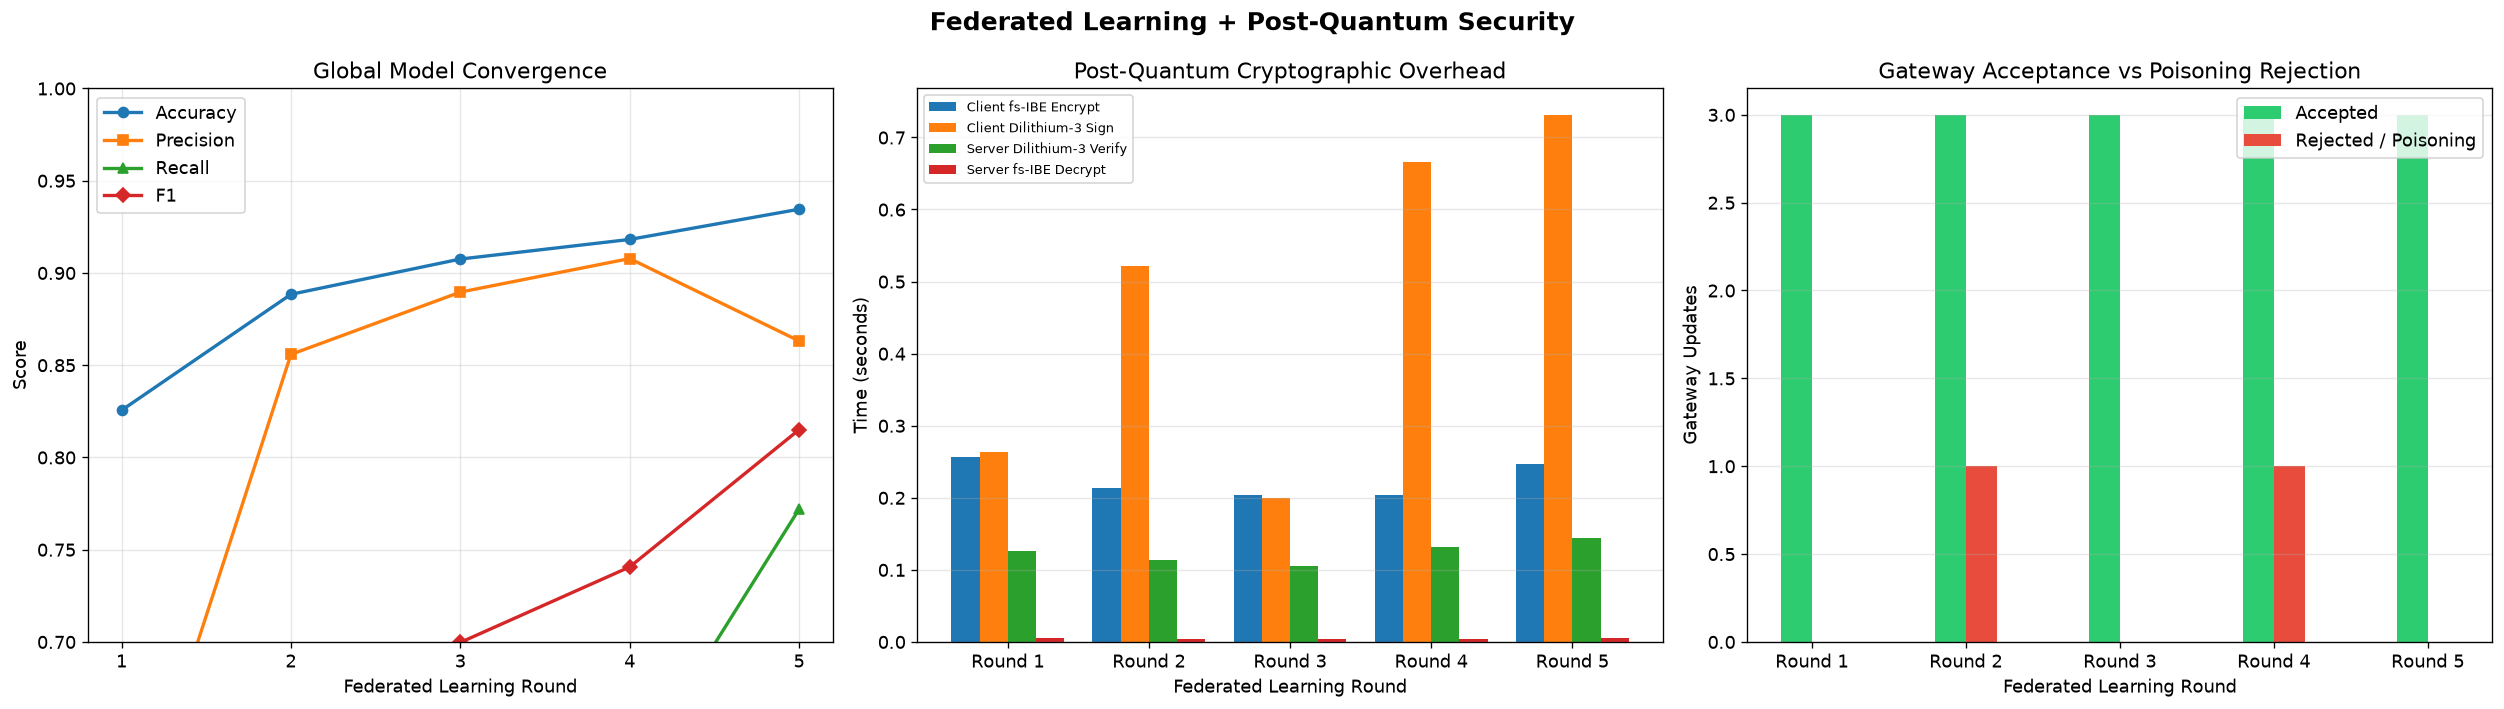

Saved: fl_detailed_analysis.png


In [13]:
from IPython.display import Image, display

fl_rounds = fl_telemetry["round"].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# Classification metrics across the five FL rounds.
for metric, label, marker in [
    ("global_accuracy", "Accuracy", "o"),
    ("global_precision", "Precision", "s"),
    ("global_recall", "Recall", "^"),
    ("global_f1", "F1", "D"),
]:
    axes[0].plot(
        fl_rounds, fl_telemetry[metric], marker=marker, linewidth=2, label=label
    )
axes[0].set_title("Global Model Convergence")
axes[0].set_xlabel("Federated Learning Round")
axes[0].set_ylabel("Score")
axes[0].set_xticks(fl_rounds)
axes[0].set_ylim(0.7, 1.0)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Grouped post-quantum cryptographic timing breakdown.
timing_metrics = [
    ("client_enc_time_s", "Client fs-IBE Encrypt"),
    ("client_sig_time_s", "Client Dilithium-3 Sign"),
    ("server_verify_time_s", "Server Dilithium-3 Verify"),
    ("server_decrypt_time_s", "Server fs-IBE Decrypt"),
]
x = np.arange(len(fl_rounds))
bar_width = 0.2
for index, (column, label) in enumerate(timing_metrics):
    axes[1].bar(
        x + (index - 1.5) * bar_width,
        fl_telemetry[column],
        bar_width,
        label=label,
    )
axes[1].set_title("Post-Quantum Cryptographic Overhead")
axes[1].set_xlabel("Federated Learning Round")
axes[1].set_ylabel("Time (seconds)")
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"Round {round_number}" for round_number in fl_rounds])
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(fontsize=8)

# Honest gateway acceptance and poisoned-update rejection.
axes[2].bar(x - bar_width / 2, fl_telemetry["accepted_gateways"],
            bar_width, label="Accepted", color="#2ecc71")
axes[2].bar(x + bar_width / 2, fl_telemetry["rejected_gateways"],
            bar_width, label="Rejected / Poisoning", color="#e74c3c")
axes[2].set_title("Gateway Acceptance vs Poisoning Rejection")
axes[2].set_xlabel("Federated Learning Round")
axes[2].set_ylabel("Gateway Updates")
axes[2].set_xticks(x)
axes[2].set_xticklabels([f"Round {round_number}" for round_number in fl_rounds])
axes[2].grid(axis="y", alpha=0.3)
axes[2].legend()

fig.suptitle("Federated Learning + Post-Quantum Security", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig("fl_detailed_analysis.png", bbox_inches="tight")
display(Image(filename="fl_detailed_analysis.png"))
plt.close(fig)
print("Saved: fl_detailed_analysis.png")

### 7.4 Live Cryptographic & Forward-Secrecy Audit

The following checks generate a real ML-DSA-65 keypair, verify an authentic
gateway update, reject tampering, and test that an epoch-1 ciphertext cannot
be decrypted after the server advances its key bundle to epoch 6.

In [14]:
from fl_aggregator import FederatedAggregatorServer
from Trust_Model import DilithiumSigner

audit_signer = DilithiumSigner()
audit_sk, audit_pk = audit_signer.keygen()
gateway_update = b"Gateway_Audit|1|32|quantized-weight-update"
gateway_signature = audit_signer.sign(gateway_update, audit_sk)
valid_update_verified = audit_signer.verify(gateway_update, gateway_signature, audit_pk)
tampered_update_verified = audit_signer.verify(
    gateway_update + b"|tampered", gateway_signature, audit_pk
)
tampered_signature = bytes([gateway_signature[0] ^ 1]) + gateway_signature[1:]
tampered_signature_verified = audit_signer.verify(
    gateway_update, tampered_signature, audit_pk
)

print(f"ML-DSA-65 public key: {len(audit_pk)} bytes")
print(f"ML-DSA-65 secret key: {len(audit_sk)} bytes")
print(f"ML-DSA-65 signature: {len(gateway_signature)} bytes")
print(f"Valid gateway update verified: {valid_update_verified}")
print(f"Tampered update payload verified: {tampered_update_verified}")
print(f"Tampered signature verified: {tampered_signature_verified}")
assert (len(audit_pk), len(audit_sk), len(gateway_signature)) == (1952, 4032, 3309)
assert valid_update_verified
assert not tampered_update_verified and not tampered_signature_verified

audit_system = P1.Setup(tree_depth=3, params=P1.LatticeParams(n=64))
audit_server = FederatedAggregatorServer(
    "Central_TA", audit_system, audit_signer, n_features=8
)
ct_epoch_1 = audit_server.ops.Encrypt(audit_server.server_id, epoch=1, bit=1)
decrypted_at_epoch_1 = audit_server.ops.Decrypt(ct_epoch_1, audit_server.key_bundle)
assert decrypted_at_epoch_1 == 1

for _ in range(5):
    audit_server.advance_epoch()
key_bundle_epoch_6 = audit_server.key_bundle.copy()
decrypted_after_evolution = audit_server.ops.Decrypt(ct_epoch_1, key_bundle_epoch_6)
print(f"Epoch-1 sample bit decrypts at epoch 1: {decrypted_at_epoch_1}")
print(f"Server advanced to epoch: {audit_server.current_epoch}")
print(f"Epoch-1 ciphertext with epoch-6 keys: {decrypted_after_evolution}")
print(f"Past update remains undecryptable: {decrypted_after_evolution is None}")
assert audit_server.current_epoch == 6
assert decrypted_after_evolution is None

ML-DSA-65 public key: 1952 bytes
ML-DSA-65 secret key: 4032 bytes
ML-DSA-65 signature: 3309 bytes
Valid gateway update verified: True
Tampered update payload verified: False
Tampered signature verified: False
Epoch-1 sample bit decrypts at epoch 1: 1
Server advanced to epoch: 6
Epoch-1 ciphertext with epoch-6 keys: None
Past update remains undecryptable: True


---
## 8. Summary & Key Findings

### What We Built
| Component | Description |
|---|---|
| **Attack Simulator** | 40,000 temporally correlated traffic windows, including 5,000 ambiguous/noisy samples |
| **Six-Model Trust Engine** | Isolation Forest, Random Forest, SVM, KNN, Decision Tree, and MLP with weighted ensemble voting |
| **Feature Extraction** | 8 behavioral features per query |
| **Trust Integration** | Ensemble decisions and signature verification drive dynamic trust adjustments |
| **Post-Quantum Signatures** | Real CRYSTALS-Dilithium-3 (ML-DSA-65) gateway keypairs and signatures |
| **Federated Gateway Client** | Local SGD + IsolationForest training, 16-bit quantization, encrypted and signed updates |
| **Federated Aggregator Server** | Trust-gated signature verification, lattice decryption, FedAvg, and binary-tree key evolution |

### Six-Model Ensemble
| Model | Role |
|---|---|
| **Isolation Forest** | Unsupervised detector for outliers and novel traffic |
| **Random Forest** | Supervised tree ensemble for known attack patterns |
| **SVM** | Supervised maximum-margin classifier |
| **KNN** | Supervised neighborhood classifier |
| **Decision Tree** | Interpretable supervised classifier |
| **MLP** | Supervised neural-network classifier |

### Key Results
The benchmark runs matched legitimate and attack episodes through the query
validator. Static trust accepts validly signed behavior attacks; the ML engine
uses the rolling feature history and ensemble to flag them.

| Metric | Static Trust | ML-Enhanced (6-model) |
|---|---:|---:|
| Accuracy | 60% | 90% |
| Precision | 100% | 100% |
| Recall | 20% | 80% |
| F1 score | 0.333 | 0.889 |
| False-positive rate | 0% | 0% |

- **Federated convergence:** Global accuracy and F1 rise across the five rounds; see the telemetry table and convergence plot above for the measured values.
- **Poisoning defense:** The tampered gateway signatures in rounds 2 and 4 are rejected; three honest gateways are accepted in every round.
- **Forward secrecy:** Verified across epochs 1-6; an epoch-1 ciphertext decrypts at epoch 1 and returns `None` with the epoch-6 key bundle.
- **Signature sizes:** Real ML-DSA-65 public key **1,952 B**, secret key **4,032 B**, and signature **3,309 B**.

### Limitations and Next Steps
- Deploy the complete ensemble, fs-IBE, and ML-DSA-65 signing path on Raspberry Pi and ESP32 edge testbeds; measure latency, memory, energy use, and key-erasure behavior under device constraints.
- Evaluate detection and cryptographic overhead using real IoT network packet captures across representative protocols and traffic conditions.
- Validate generalization across devices and sites, report per-attack metrics and confidence intervals, and tune thresholds to control false positives before production use.

### Novelty
> **Three-Pillar Novelty of Our Major Project Architecture:**
> 1. **Dual Post-Quantum Cryptographic Stack:** Combines **Dual Regev Lattice-Based Forward-Secure IBE (`fs-IBE`)** for epoch-bound confidentiality with real **NIST FIPS 204 CRYSTALS-Dilithium-3 (`ML-DSA-65`)** lattice signatures (`PK = 1,952 B`, `Sig = 3,309 B`) for unforgeable gateway and device authentication.
> 2. **Forward-Secure Federated Learning (`fs-IBE + FedAvg`):** Edge gateways train local behavioral models on private traffic and encrypt quantized 16-bit weight updates under the current epoch key. Because the central server evolves its secret key via binary-tree Minimal Cover (`MinCov`) and erases `sk_t` after each round, compromise of the server at epoch `t+k` cannot expose historical model updates from earlier epochs.
> 3. **Byzantine-Resilient Behavioral Trust Gating:** Integrates an 8-feature six-model ML trust engine (Isolation Forest, Random Forest, SVM, KNN, Decision Tree, and MLP) with signature verification to block flood, replay, Sybil, probing, and model-poisoning attacks.

### Files Structure
```
Project/
|-- lattice_infrastructure.py   # P1: Lattice primitives
|-- forward_security.py         # P2: fs-IBE Encrypt/Decrypt
|-- Trust_Model.py              # P3: Enhanced trust + feature extraction
|-- simulation.py               # P4: Full pipeline benchmarking
|-- attack_simulator.py         # 40,000-window normal, attack, and ambiguous traffic
|-- ml_trust_engine.py          # Six-model ML trust engine
|-- ml_simulation.py            # NEW: ML comparison benchmarks
|-- federated_trust.py          # Dilithium-signed FL gateway client
|-- fl_aggregator.py            # Lattice fs-IBE FedAvg server
|-- fl_simulation.py            # Five-round end-to-end federated simulation
|-- models/                     # Saved ML models (joblib)
|-- training_data.csv           # Generated training dataset
|-- Results_Report.csv          # Base pipeline metrics
|-- ML_Trust_Comparison.csv     # Static vs ensemble comparison metrics
|-- FL_Results_Report.csv       # Federated learning round metrics
|-- fl_convergence.png          # FL accuracy/F1 and crypto latency plot
|-- fl_detailed_analysis.png    # Detailed FL metrics, crypto overhead, and gateway acceptance
|-- fl_simulation_results.json  # Federated learning round telemetry
|-- Forward_Secure_Lattice_IBE.ipynb     # Minor project notebook
|-- Major_Project_ML_Trust_Scoring_1.ipynb # Teammate's six-model source notebook
|-- Major_Project_ML_Trust_Scoring.ipynb # THIS notebook (Major project)
```